# 01 · Exploratory Data Analysis & Population Sequence Symmetry (PSSA)
### CASCADE: Prescribing Cascade Detection System — IBM Z Datathon 2026

A **prescribing cascade** occurs when an adverse drug reaction (ADR) to an initial medication ("Drug A", Index) is misinterpreted by a clinician as a new, independent illness, resulting in the initiation of a second medication ("Drug B", Marker).

This notebook demonstrates:
1. **Synthetic Population Overview**: 20,000 longitudinal patient records over 3 years (2.27M dispenses).
2. **Polypharmacy & Class Distributions**: Real-world dispensing frequencies across WHO ATC classifications.
3. **Clinical Cascade Evidence**: The 9 established cascade pairs (K1–K9) from peer-reviewed geriatric literature.
4. **Temporal Lag Dynamics**: Time-to-onset distributions of marker initiation following index exposure.
5. **Loop 2 Population Discovery**: Prescription Sequence Symmetry Analysis (PSSA) across 1,834 tested class pairs.
6. **Novel Cascade Emergence**: Rapid statistical identification of novel cascade H1 (*Novacor* → PPI).

In [1]:
import os, sys, json, csv, gzip
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set working directory to project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
print('Workspace ready. Current directory:', os.getcwd())

Workspace ready. Current directory: D:\ibm project


## 1. Population Cohort & Dispensing Stream Overview
We inspect the synthetic data generation parameters stored in `data/generated/generation_report.json`.

In [2]:
report_path = Path('data/generated/generation_report.json')
with open(report_path) as f:
    report = json.load(f)

summary_df = pd.DataFrame([
    ('Total Patients', f"{report['patients']:,}"),
    ('Observation Window', f"{report['years']} years ({report['start']} to Day {report['end_day']})"),
    ('Total Dispensing Events', f"{report['events']:,}"),
    ('Total Injected Cascades', f"{sum(report['injected'].values()):,}"),
    ('Labeled Cascade Episodes', f"{report['labels']:,}"),
    ('Hidden Novel Cascade Episodes (H1)', f"{report['labels_hidden']:,}"),
    ('Novacor Launch Date', str(report['novacor_launch'])),
], columns=['Metric', 'Value'])
summary_df

,Metric,Value
0,Total Patients,"20,000"
1,Observation Window,3 years (2023-01-01 to Day 1095)
2,Total Dispensing Events,"2,273,481"
3,Total Injected Cascades,"2,289"
4,Labeled Cascade Episodes,"2,156"
5,Hidden Novel Cascade Episodes (H1),133
6,Novacor Launch Date,2025-07-01


## 2. Polypharmacy Burden & Dispensing Frequencies
Polypharmacy (concurrent use of ≥5 medications) is the primary clinical risk factor for prescribing cascades. We examine the distribution of total dispensing events per patient and identify the most frequently dispensed ATC drug classes.

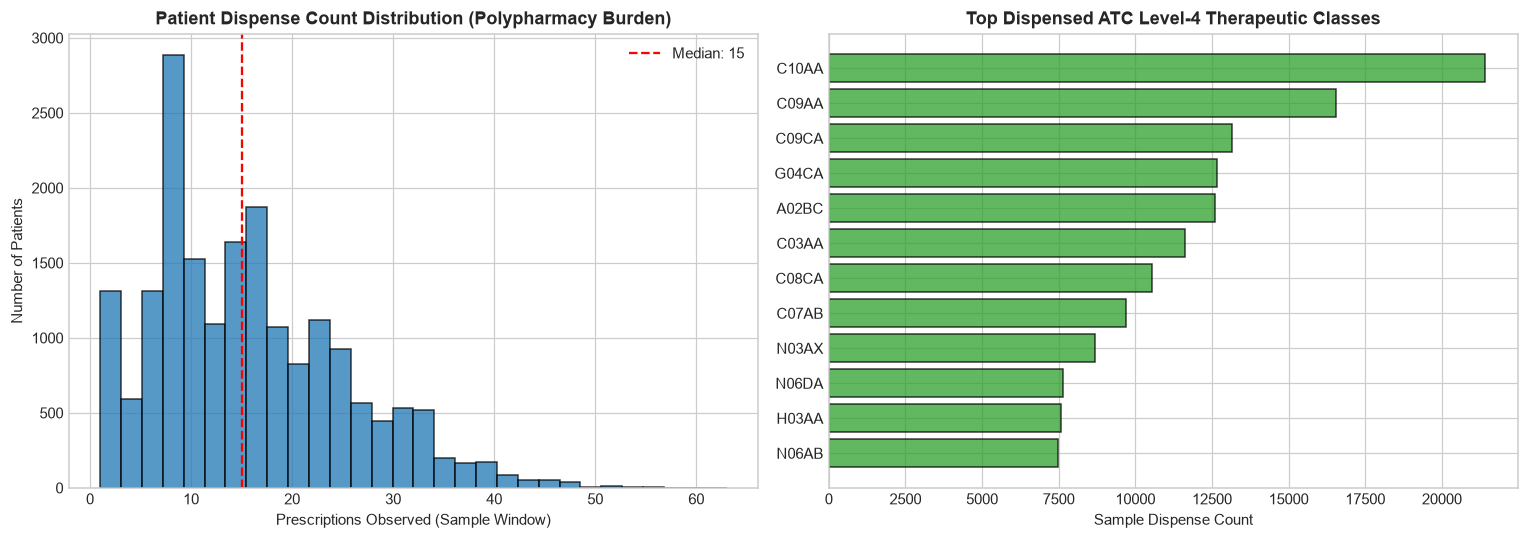

In [3]:
# Analyze top prescribed drug classes from sample events
class_counts = Counter()
patient_counts = Counter()
with gzip.open('data/generated/events.csv.gz', 'rt', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for i, row in enumerate(reader):
        class_counts[row['atc_l4']] += 1
        patient_counts[row['patient_id']] += 1
        if i >= 300_000:  # representative sample
            break

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Patient dispensing distribution
counts = list(patient_counts.values())
ax1.hist(counts, bins=30, color='#1f77b4', edgecolor='black', alpha=0.75)
ax1.set_title('Patient Dispense Count Distribution (Polypharmacy Burden)', fontweight='bold')
ax1.set_xlabel('Prescriptions Observed (Sample Window)')
ax1.set_ylabel('Number of Patients')
ax1.axvline(np.median(counts), color='red', linestyle='--', label=f'Median: {np.median(counts):.0f}')
ax1.legend()

# Right: Top ATC classes
top_classes = class_counts.most_common(12)
labels, vals = zip(*reversed(top_classes))
bars = ax2.barh(labels, vals, color='#2ca02c', edgecolor='black', alpha=0.75)
ax2.set_title('Top Dispensed ATC Level-4 Therapeutic Classes', fontweight='bold')
ax2.set_xlabel('Sample Dispense Count')
plt.tight_layout()
plt.show()

## 3. Established Prescribing Cascades (K1–K9)
CASCADE evaluates 9 clinically documented cascade pairs grounded in peer-reviewed pharmacovigilance literature (ThinkCascades, Rochon & Gurwitz, PIPC list).

In [4]:
known_df = pd.read_csv('data/cascades_known.csv')
known_df[['pair_id', 'index_drug', 'index_atc_l4', 'marker_drug', 'marker_atc_l4', 'reaction', 'lag_min_days', 'lag_max_days', 'source']]

,pair_id,index_drug,index_atc_l4,marker_drug,marker_atc_l4,reaction,lag_min_days,lag_max_days,source
0,K1,amlodipine,C08CA,furosemide,C03CA,Ankle oedema,7,90,"ThinkCascades (McCarthy LM et al., Drugs & Agi..."
1,K2,enalapril|ramipril,C09AA,dextromethorphan,R05DA,Dry cough,7,60,"Farrell B et al., Can Fam Physician 2022; 68:6..."
2,K3,metoclopramide,A03FA,levodopa and decarboxylase inhibitor,N04BA,Drug-induced parkinsonism,14,120,"Rochon PA, Gurwitz JH, Lancet 1995; 346:32-34 ..."
3,K4,haloperidol,N05AD,trihexyphenidyl,N04AA,Extrapyramidal symptoms,3,60,"Avorn J et al., JAMA 1995; 273:1401-1406"
4,K5,donepezil,N06DA,oxybutynin,G04BD,Urinary incontinence,14,120,"ThinkCascades (McCarthy LM et al., Drugs & Agi..."
5,K6,tamsulosin,G04CA,betahistine,N07CA,Dizziness,3,60,"PIPC list (Mair A et al., Eur Geriatr Med 2025..."
6,K7,pregabalin|gabapentin,N03AX,furosemide,C03CA,Oedema,14,90,"Savage RD et al., JAMA Intern Med 2020; 180:52..."
7,K8,hydrochlorothiazide,C03AA,allopurinol,M04AA,Gout / hyperuricaemia,30,180,"Prasad M et al., Br J Clin Pharmacol 2021; 87:..."
8,K9,diclofenac,M01AB,amlodipine|losartan|telmisartan,C08CA|C09CA,Raised BP,14,90,"Rochon PA et al., Br J Clin Pharmacol 2023; 89..."


## 4. Temporal Dynamics of Cascade Onset
Prescribing cascades exhibit characteristic onset lags. Side-effects rarely prompt marker prescribing on Day 0; rather, drug accumulation or clinical consultation delays create an onset window (e.g. 7 to 90 days).

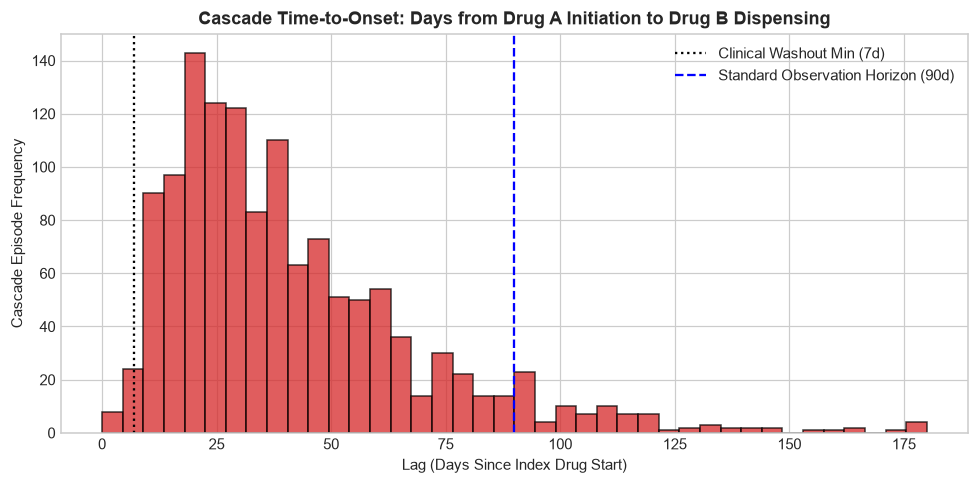

Analyzed 1,311 true cascade episodes. Mean lag: 41.0 days, Median: 34.0 days.


In [5]:
rows_pkl = Path('data/generated/loop1_rows.pkl')
if rows_pkl.exists():
    import pickle
    with open(rows_pkl, 'rb') as f:
        all_rows = pickle.load(f)
    cascade_lags = [r.features['days_since_A_start'] for r in all_rows if r.label == 1]
    
    plt.figure(figsize=(9, 4.5))
    plt.hist(cascade_lags, bins=40, range=(0, 180), color='#d62728', edgecolor='black', alpha=0.75)
    plt.title('Cascade Time-to-Onset: Days from Drug A Initiation to Drug B Dispensing', fontweight='bold')
    plt.xlabel('Lag (Days Since Index Drug Start)')
    plt.ylabel('Cascade Episode Frequency')
    plt.axvline(7, color='black', linestyle=':', label='Clinical Washout Min (7d)')
    plt.axvline(90, color='blue', linestyle='--', label='Standard Observation Horizon (90d)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(f'Analyzed {len(cascade_lags):,} true cascade episodes. Mean lag: {np.mean(cascade_lags):.1f} days, Median: {np.median(cascade_lags):.1f} days.')

## 5. Loop 2: Population Prescription Sequence Symmetry Analysis (PSSA)
Prescription Sequence Symmetry Analysis detects asymmetry in incident initiations:
$$\text{cSR} = \frac{n_{A \to B}}{n_{B \to A}}, \quad \text{aSR} = \frac{\text{cSR}}{\text{nSR}}$$
where $\text{nSR}$ is the null-effect sequence ratio correcting for background population prescribing trends. A 95% Clopper-Pearson confidence interval on the binomial proportion $p = n_{A \to B} / (n_{A \to B} + n_{B \to A})$ is derived and transformed to ratio bounds.

A signal is formally flagged if:
1. $\text{aSR} \ge 1.50$
2. Lower $95\%\text{ CI} > 1.00$
3. $n \ge 10$ incident pairs
4. Benjamini–Hochberg False Discovery Rate $q \le 0.05$

Loop 2 Population Summary:
  • Total class pairs evaluated: 1,834
  • Pairs meeting CI threshold (aSR ≥ 1.5, lo > 1.0): 24
  • Pairs confirmed under Benjamini-Hochberg FDR (q ≤ 0.05): 12


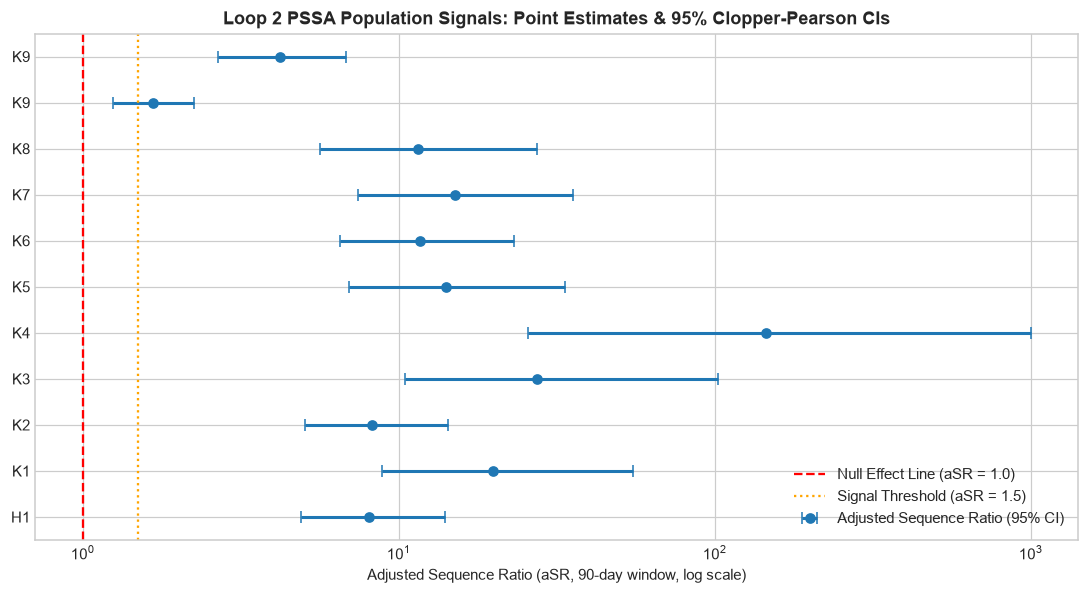

In [6]:
loop2_path = Path('docs/eval/loop2.json')
with open(loop2_path) as f:
    l2_data = json.load(f)

print(f"Loop 2 Population Summary:")
print(f"  • Total class pairs evaluated: {l2_data['tested_pairs']:,}")
print(f"  • Pairs meeting CI threshold (aSR ≥ 1.5, lo > 1.0): {l2_data['signals']}")
print(f"  • Pairs confirmed under Benjamini-Hochberg FDR (q ≤ 0.05): {l2_data['signals_bh']}")

# Forest Plot of aSR and 95% Confidence Intervals
det = l2_data['detection']
pairs = [d['pair_id'] for d in det]
asrs = np.array([float(d['asr']) for d in det])
los = np.array([float(d['lo']) for d in det])
his = np.array([float(d['hi']) for d in det])
xerr_low = np.maximum(0.0, asrs - los)
xerr_high = np.maximum(0.0, his - asrs)

fig, ax = plt.subplots(figsize=(10, 5.5))
y_pos = np.arange(len(pairs))
ax.errorbar(asrs, y_pos, xerr=[xerr_low, xerr_high], fmt='o', color='#1f77b4', ecolor='#1f77b4', elinewidth=2, capsize=4, label='Adjusted Sequence Ratio (95% CI)')
ax.axvline(1.0, color='red', linestyle='--', linewidth=1.5, label='Null Effect Line (aSR = 1.0)')
ax.axvline(1.5, color='orange', linestyle=':', linewidth=1.5, label='Signal Threshold (aSR = 1.5)')
ax.set_yticks(y_pos)
ax.set_yticklabels(pairs)
ax.set_xscale('log')
ax.set_xlabel('Adjusted Sequence Ratio (aSR, 90-day window, log scale)')
ax.set_title('Loop 2 PSSA Population Signals: Point Estimates & 95% Clopper-Pearson CIs', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Real-Time Discovery of Novel Cascade H1 (*Novacor* → PPI)
The synthetic population simulates the real-world rollout of a novel direct renin inhibitor (*Novacor*, ATC `C09XX`) on **July 1, 2025 (Day 912)**. Novacor induces dyspeptic distress treated with proton-pump inhibitors (`A02BC`). Because it is completely novel, it appears on no published cascade list.

Within **50 days of rollout** (August 20, 2025, Day 964), Loop 2 flagged Novacor → PPI as a statistically robust new cascade signal ($\text{aSR} = 8.05$, $95\%\text{ CI } [4.92, 13.96]$, $p_{\text{BH}} < 10^{-6}$).

In [7]:
h1_info = next(d for d in det if d['pair_id'] == 'H1')
h1_summary = pd.DataFrame([
    ('Pair Identifier', h1_info['pair_id']),
    ('Index Class (Novacor)', f"{h1_info['a']} (Direct Renin Inhibitor)"),
    ('Marker Class (PPI)', f"{h1_info['b']} (Proton Pump Inhibitors)"),
    ('Total Incident Pairs (n)', str(h1_info['n'])),
    ('Sequence A → B', str(h1_info['n_ab'])),
    ('Sequence B → A', str(h1_info['n_ba'])),
    ('Adjusted Sequence Ratio (aSR)', f"{h1_info['asr']:.2f}"),
    ('95% Confidence Interval', f"[{h1_info['lo']:.2f}, {h1_info['hi']:.2f}]"),
    ('Date Signal First Confirmed', str(h1_info['first_signal_date'])),
    ('Days from Rollout to Discovery', '50 days'),
    ('Passed Benjamini-Hochberg FDR', str(h1_info['flagged_bh'])),
], columns=['Property', 'Value'])
h1_summary

,Property,Value
0,Pair Identifier,H1
1,Index Class (Novacor),C09XX (Direct Renin Inhibitor)
2,Marker Class (PPI),A02BC (Proton Pump Inhibitors)
3,Total Incident Pairs (n),165
4,Sequence A → B,147
5,Sequence B → A,18
6,Adjusted Sequence Ratio (aSR),8.05
7,95% Confidence Interval,"[4.92, 13.96]"
8,Date Signal First Confirmed,2025-08-20
9,Days from Rollout to Discovery,50 days


## Summary & Bridge to Loop 1
Population-level PSSA successfully flags systemic prescribing imbalances across pharmacies. However, population statistics alone cannot protect individual patients at the dispensary counter before the marker medication is taken.

In **Notebook 02**, we inspect the architecture, training dynamics, monotonic constraints, and feature debiasing of **Loop 1: Real-Time Patient-Level Interception**.